# Automatic Image Colorization (Hybrid U-Net & Zhang Classification)
**Authors:** Malwina Belczewska and Oliwier Mróz
---
## Project Goal
The goal of this project is to create an advanced artificial intelligence system capable of automatically and photorealistically restoring colors to black and white photographs. We accomplish this task using a proprietary hybrid architecture based on the **U-Net** network (with a pre-trained encoder) and an innovative color classification approach proposed by **Richard Zhang (2016)**.

---

## Methodology and Data Pipeline
Most standard neural networks treat colorization as a continuous regression problem (guessing the exact color value and minimizing L1/MSE error). This leads to "safe guessing" — when the network is uncertain whether an object was, for example, red or blue, it averages the result, frustratingly producing faded, grayish images.

Our project effectively solves this problem by implementing the main assumptions of the **Zhang algorithm**:

1. **Color Space Discretization:** Instead of smooth, infinite colors, the mathematical CIELab color space (color components *ab*) is divided into **313 distinct "bins"** (classes).
2. **Colorization as Classification:** Our network no longer guesses "on a slider" for numerical values. Instead, for each pixel it computes the probability of belonging to one of 313 predefined, vibrant colors.
3. **Transfer Learning (Hybrid U-Net):** The role of the "brain" (encoder) is fulfilled by a powerful, pre-trained **EfficientNet-B4** network. It extracts advanced semantic features from the photograph (recognizes textures, faces, objects), while the U-Net decoder with skip connections ensures perfect edge preservation without color bleeding.

### Input and Output Data Specification:
* **Input Data (Input / Condition):** An image from the COCO 2017 dataset converted to the CIELab color space. The network receives the **lightness channel (L) replicated three times** as a three-channel tensor (dimensions: $256 \times 256 \times 3$). Replication preserves the full weights of the pre-trained EfficientNet-B4 encoder.
* **Target Data (Target / Ground Truth):** Original color channels (*a, b*) mapped (mathematically assigned) to indices of the nearest of 313 Zhang color bins.
* **Output Data (Output):** A map of dimensions $256 \times 256 \times 313$, representing a probability distribution over individual colors. From it, the final *ab* channels are reconstructed, which when combined with the input *L* channel produce a fully colorized RGB image.

---

## Notebook Table of Contents
1. Imports and environment configuration
2. Data pipeline — `COCOColorizationDataset` class (pre-training)
3. Training data preview
4. Architecture — U-Net + EfficientNet-B4 (313 classes)
5. Generator training (pre-training)
6. Pre-training results visualization
7. Data pipeline — `COCOColorizationDatasetGAN` class
8. Discriminator architecture — PatchGAN
9. GAN training (5 epoch warmup)
10. GAN results visualization
11. Final fine-tuning
12. Final summary

In [ ]:
import warnings
warnings.filterwarnings("ignore")
from PIL import Image, ImageOps
from skimage import color
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm
from skimage.color import rgb2lab, lab2rgb
import glob
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
import urllib.request
import torch.nn.functional as F
import torchvision.models as tvm
import segmentation_models_pytorch as smp
from torch.nn.utils import spectral_norm


In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Ustawiono ziarno (seed): {seed}")
set_seed(42)

Ustawiono ziarno (seed): 42


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == 'cuda':
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM: {vram_gb:.1f} GB")
else:
    print("Computing on: CPU")

# ==========================================
# COLOR SPACE DISCRETIZATION (313 BINS)
# Instead of guessing the exact shade, we force the network to choose
# one of 313 predefined colors in the CIELAB color space.
url_pts = "https://raw.githubusercontent.com/richzhang/colorization/caffe/colorization/resources/pts_in_hull.npy"
if not os.path.exists("pts_in_hull.npy"):
    urllib.request.urlretrieve(url_pts, "pts_in_hull.npy")

pts = np.load("pts_in_hull.npy")
print(f"Color bins loaded. Shape: {pts.shape} (313 colors, 2 channels a*b*)")

# ==========================================
# CLASS BALANCING (REBALANCING)
# ==========================================
# Natural photographs are mostly grayscale, backgrounds, and faded colors.
# Without intervention, the network colorizes everything to safe sepia tones.
url_probs = "https://raw.githubusercontent.com/richzhang/colorization/caffe/colorization/resources/prior_probs.npy"
if not os.path.exists("prior_probs.npy"):
    urllib.request.urlretrieve(url_probs, "prior_probs.npy")

prior_probs = np.load("prior_probs.npy")

# We mix the natural frequency of color occurrence with equal chance for each color (lambda = 0.5).
# This artificially boosts the importance of rare colors in the dataset.
uniform_probs = np.ones_like(prior_probs) / len(prior_probs)
mix_probs = 0.5 * prior_probs + 0.5 * uniform_probs

# We calculate the weights:
# This "rewards" the model during training for taking the risk of using vibrant colors.
weights = 1.0 / mix_probs
weights = weights / np.sum(prior_probs * weights) # Normalize sum to 1

class_weights = torch.from_numpy(weights).float().to(device)
print(f"Done! Weights for {len(class_weights)} classes sent to device: {device}.")

GPU: NVIDIA GeForce RTX 3060 | VRAM: 12.9 GB
Załadowano koszyki barw. Kształt: (313, 2) (313 kolorów, 2 kanały a*b*)
Gotowe! Wagi dla 313 klas przesłane na urządzenie: cuda.


---
# Dataset Analysis and Function Definitions
### Dataset Configuration
We define paths to COCO 2017 folders and create `DataLoaders` that provide data to the model.

**Structure:**
* `train2017`: Main dataset for training the model.
* `val2017`: Dataset for monitoring progress (checking "live" that the model is not overfitting).
* `test2017`: "Blind" dataset for final evaluation of colorization quality on unseen images.

### Data Pipeline — CIELab + Zhang Quantization

The `COCOColorizationDataset` class processes images **in-memory** (without saving to disk),
providing ready tensors directly to the `DataLoader`.

**Processing per sample:**

| Step | Details |
|---|---|
| Resize | $256 \times 256$ px, LANCZOS filter |
| Conversion | RGB → CIELab |
| Network Input | Channel $L \in [0, 1]$, shape `[1, H, W]` |
| Network Target | Bin index $q \in \{0, \ldots, 312\}$ per pixel, shape `[H, W]` |
| Filtering | Images with $\sigma(ab) < 0.5$ rejected (practically B&W) |

**Quantization** — each pixel $ab$ mapped to the nearest Zhang centroid:

$$q^*_{h,w} = \underset{q}{\arg\min}\ \bigl\| ab_{h,w} - c_q \bigr\|_2, \quad c_q \in \mathbb{R}^{313 \times 2}$$

**Augmentations** (training only): `RandomHorizontalFlip` + `RandomResizedCrop(scale=0.8–1.0)`
+ lightness perturbation $L \leftarrow \text{clip}(\alpha L,\ 0, 1),\ \alpha \sim \mathcal{U}(0.85, 1.15)$.

In [ ]:
class COCOColorizationDataset(Dataset):
    def __init__(self, raw_dir, pts, img_size=512, max_imgs=5000, augment=False):
        self.raw_dir = raw_dir
        self.image_files = [f for f in os.listdir(raw_dir) if f.endswith('.jpg')][:max_imgs]
        self.resize = transforms.Resize((img_size, img_size), Image.Resampling.LANCZOS)
        self.img_size = img_size
        self.augment = augment

        # We store the 313 Zhang bins as a tensor
        self.pts = torch.from_numpy(pts).float()

        # --- AUGMENTATIONS (only geometric and brightness — we DO NOT change colors!) ---
        self.augmentation = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),

            transforms.RandomResizedCrop(
                size=(img_size, img_size),
                scale=(0.8, 1.0),
                ratio=(0.9, 1.1),
                interpolation=Image.Resampling.LANCZOS
            ),

        ]) if augment else None

        self.brightness_range = (0.85, 1.15) if augment else None

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        while True:
            img_path = os.path.join(self.raw_dir, self.image_files[idx])
            img = Image.open(img_path).convert("RGB")
            img = self.resize(img)

            # --- GEOMETRIC AUGMENTATIONS (on PIL image before conversion to Lab) ---
            if self.augment and self.augmentation is not None:
                img = self.augmentation(img)

            img_lab = rgb2lab(np.array(img)).astype(np.float32)

            # --- FILTERING BLACK AND WHITE IMAGES ---
            ab_channels = img_lab[:, :, 1:]
            if np.std(ab_channels) < 0.5:
                idx = np.random.randint(0, len(self.image_files))
                continue

            break

        # --- NORMALIZATION OF L CHANNEL ---
        # L ∈ [0, 100] → scale to [0, 1] for training stability
        L = img_lab[:, :, 0] / 100.0

        # --- BRIGHTNESS AUGMENTATION ON L CHANNEL ---
        if self.augment and self.brightness_range is not None:
            brightness_factor = random.uniform(*self.brightness_range)
            L = np.clip(L * brightness_factor, 0.0, 1.0)

        ab = img_lab[:, :, 1:]

        L_tensor = torch.from_numpy(L).unsqueeze(0)        # Shape: (1, H, W)
        ab_tensor = torch.from_numpy(ab)                    # Shape: (H, W, 2)

        # --- ZHANG QUANTIZATION (assign pixels to nearest ab bin) ---
        # 1. Flatten ab map to pixel list: (H*W, 2)
        # 2. Compute Euclidean distance of each pixel from each of 313 centroids
        # 3. Select bin index with smallest distance
        # 4. Restore spatial shape: (H*W,) → (H, W), values 0–312
        ab_flat = ab_tensor.view(-1, 2)

        distances = torch.cdist(ab_flat, self.pts)

        target_classes_flat = torch.argmin(distances, dim=1)

        target_tensor = target_classes_flat.view(self.img_size, self.img_size).long()

        return L_tensor, target_tensor

In [ ]:
TRAIN_DIR = r"D:\Data\coco2017\train2017"
VAL_DIR   = r"D:\Data\coco2017\val2017"

train_dataset = COCOColorizationDataset(
    raw_dir=TRAIN_DIR, pts=pts, img_size=256, max_imgs=30000, augment=True)

val_dataset = COCOColorizationDataset(
    raw_dir=VAL_DIR, pts=pts, img_size=256, max_imgs=1000, augment=False)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True, drop_last=True,
    num_workers=0, pin_memory=True, persistent_workers=False)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False, drop_last=False,
    num_workers=0, pin_memory=True, persistent_workers=False)

print(f"Training batches: {len(train_loader)} | Validation: {len(val_loader)}")

L_batch, target_batch = next(iter(train_loader))
print(f"L: {L_batch.shape} | target: {target_batch.shape}")

Paczki treningowe: 3750 | Walidacyjne: 125
L: torch.Size([8, 1, 256, 256]) | target: torch.Size([8, 256, 256])


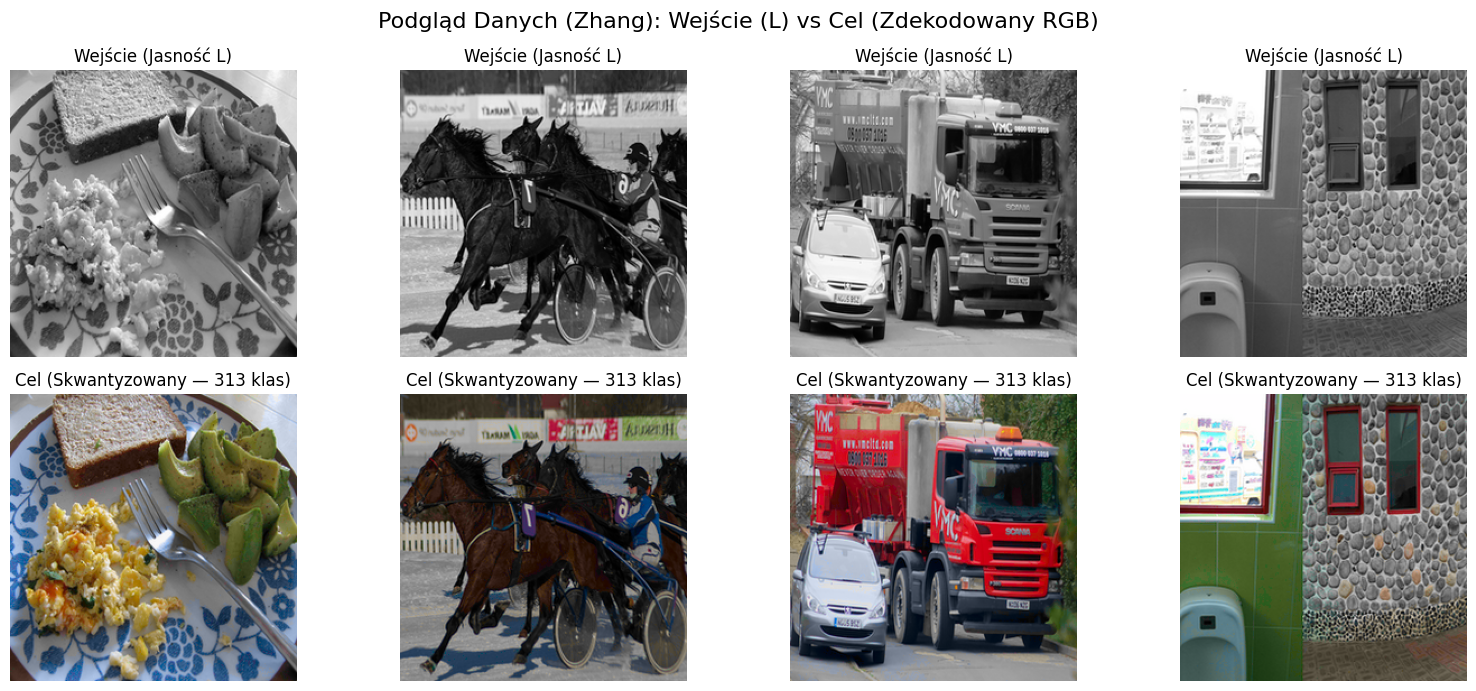

In [ ]:
L_batch, target_batch = next(iter(train_loader))
num_imgs = min(4, L_batch.size(0))

# squeeze=False solves indexing issues for batch_size=1
fig, axes = plt.subplots(2, num_imgs, figsize=(16 if num_imgs > 1 else 8, 7), squeeze=False)
fig.suptitle("Data Preview (Zhang): Input (L) vs Target (Decoded RGB)", fontsize=16)

for i in range(num_imgs):
    L_img = L_batch[i].squeeze(0).numpy()
    L_unnorm = L_batch[i].permute(1, 2, 0).numpy() * 100.0
    idx_map = target_batch[i].numpy()
    ab_unnorm = pts[idx_map]
    lab_img = np.concatenate([L_unnorm, ab_unnorm], axis=2)
    rgb_img = lab2rgb(lab_img)
    axes[0, i].imshow(L_img, cmap='gray')
    axes[0, i].set_title("Input (Lightness L)")
    axes[0, i].axis('off')
    axes[1, i].imshow(rgb_img)
    axes[1, i].set_title("Target (Quantized — 313 classes)")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

---
# U-Net Model Architecture

---
## Architecture — U-Net + EfficientNet-B4 (313 classes)

Colorization as **per-pixel classification** in Zhang color space (313 ab bins).

**Encoder — EfficientNet-B4:**
Repeatedly stacked convolutional blocks that gradually "compress" the image — reduce spatial dimensions while increasing the number of channels (features). For 256×256 input:

| Stage | Resolution | Channels |
|------|--------------|--------|
| Stem | 128×128 | 48 |
| Stage 1–2 | 64×64 | 32 |
| Stage 3–4 | 32×32 → 16×16 | 56 → 112 |
| Bottleneck | 8×8 | 448 |

- **in_channels = 3** — L channel replicated ×3 so the encoder receives full ImageNet weights

**Decoder — U-Net:**
Symmetric path that restores spatial resolution back to 256×256. At each step it combines the decoder feature map with a **skip connection** from the corresponding encoder stage — this way the model doesn't lose fine spatial details. Output: 313 logits per pixel (no activation — CrossEntropy expects raw logits).

**Loss functions:**
- `ZhangRebalancedLoss` — CrossEntropyLoss with class weights balancing rare colors in COCO (e.g., blue and red appear less frequently than browns — without rebalancing the model would ignore them)


In [ ]:
class ColorizationUNet(nn.Module):
    def __init__(self, num_bins=313):
        super().__init__()
        self.unet = smp.Unet(
            encoder_name="efficientnet-b4",
            encoder_weights="imagenet",
            in_channels=3,
            classes=num_bins,
            activation=None
        )

    def forward(self, L):
        # L: (B, 1, H, W) → replicate to (B, 3, H, W) to preserve full ImageNet weights
        return self.unet(L.repeat(1, 3, 1, 1))   # (B, 313, H, W)


class ZhangRebalancedLoss(nn.Module):
    def __init__(self, class_weights):
        super().__init__()
        self.loss = nn.CrossEntropyLoss(weight=class_weights)

    def forward(self, logits, targets):
        return self.loss(logits, targets)


criterion = ZhangRebalancedLoss(class_weights)

### Pre-Training U-Net

We formulate the colorization problem as **per-pixel classification** — the network assigns each pixel one of 313 ab color bins (Zhang quantization).

**Loss functions:** `ZhangRebalancedLoss`

**Training mechanisms:** gradient accumulation (every 4 steps), mixed precision (AMP), early stopping (patience=7), ReduceLROnPlateau scheduler (×0.5 every 3 epochs without improvement).

In [ ]:
def train_model_1(
    model, train_loader, val_loader, class_weights,
    epochs=10,
    lr=3e-4,
    device="cuda",
    patience=7,
    accumulation_steps=4,
    lambda_zhang=1.0,
):
    criterion  = ZhangRebalancedLoss(class_weights)
    optimizer  = optim.Adam(model.parameters(), lr=lr)
    scheduler  = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3, verbose=True)
    scaler     = torch.amp.GradScaler('cuda')

    train_losses, val_losses = [], []
    best_val_loss   = float('inf')
    epochs_no_improve = 0

    print(f"Starting training | Epochs: {epochs} | LR: {lr} | λ_zhang: {lambda_zhang}")

    for epoch in range(epochs):
        model.train()
        running_train_loss = 0.0
        optimizer.zero_grad()
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Training]")

        for i, (inputs, targets) in enumerate(train_pbar):
            inputs  = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                logits = model(inputs)                          # (B, 313, H, W)
                loss   = lambda_zhang * criterion(logits, targets) / accumulation_steps

            scaler.scale(loss).backward()

            if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

            running_train_loss += (loss.item() * accumulation_steps) * inputs.size(0)
            train_pbar.set_postfix({"Loss": f"{loss.item()*accumulation_steps:.4f}",
                                    "LR":   f"{optimizer.param_groups[0]['lr']:.2e}"})

        epoch_train_loss = running_train_loss / len(train_loader.dataset)

        # --- VALIDATION ---
        model.eval()
        running_val_loss = 0.0
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Validation]")
        with torch.no_grad():
            for inputs, targets in val_pbar:
                inputs  = inputs.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    logits    = model(inputs)
                    loss_val  = criterion(logits, targets)
                running_val_loss += loss_val.item() * inputs.size(0)
                val_pbar.set_postfix({"Loss": f"{loss_val.item():.4f}"})

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        scheduler.step(epoch_val_loss)

        print(f">>> Epoch {epoch+1}: Train = {epoch_train_loss:.4f} | "
              f"Val = {epoch_val_loss:.4f} | LR = {optimizer.param_groups[0]['lr']:.2e}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            epochs_no_improve = 0
            torch.save({
                'epoch': epoch+1,
                'model_state_dict':     model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'best_val_loss':        best_val_loss,
                'train_losses':         train_losses,
                'val_losses':           val_losses,
            }, "unet_pretrained_best.pth")
            print(f"[*] Checkpoint saved. (Val: {best_val_loss:.4f})\n")
        else:
            epochs_no_improve += 1
            print(f"[-] No improvement for {epochs_no_improve}/{patience} epochs.\n")
            if epochs_no_improve >= patience:
                print(f"!!! Early Stopping after {epoch+1} epochs.")
                break

    torch.save(model.state_dict(), "unet_pretrained.pth")
    print("Final model saved.")
    return train_losses, val_losses

In [ ]:
model = ColorizationUNet().to(device)
train_losses, val_losses = train_model_1(model, train_loader, val_loader, class_weights)

Rozpoczęcie treningu | Epoki: 10 | LR: 0.0003 | λ_zhang: 1.0 | λ_perc: 0.1


Epoka 1/10 [Walidacja]: 100%|███████████████████████████████████████████| 125/125 [01:58<00:00,  1.05it/s, Loss=3.0636]


>>> Epoka 1: Train = 4.2067 | Val = 3.8521 | LR = 3.00e-04
[*] Checkpoint zapisany. (Val: 3.8521)



Epoka 2/10 [Walidacja]: 100%|███████████████████████████████████████████| 125/125 [01:32<00:00,  1.36it/s, Loss=3.0137]


>>> Epoka 2: Train = 3.8936 | Val = 3.7487 | LR = 3.00e-04
[*] Checkpoint zapisany. (Val: 3.7487)



...

>>> Epoka 8: Train = 3.5554 | Val = 3.7390 | LR = 3.00e-04
[-] Brak poprawy od 1/7 epok.



Epoka 9/10 [Walidacja]: 100%|███████████████████████████████████████████| 125/125 [01:25<00:00,  1.46it/s, Loss=2.8858]


>>> Epoka 9: Train = 3.5158 | Val = 3.7399 | LR = 3.00e-04
[-] Brak poprawy od 2/7 epok.



Epoka 10/10 [Walidacja]: 100%|██████████████████████████████████████████| 125/125 [01:20<00:00,  1.55it/s, Loss=2.8452]


>>> Epoka 10: Train = 3.4703 | Val = 3.7576 | LR = 3.00e-04
[-] Brak poprawy od 3/7 epok.

Zapisano finalny model.


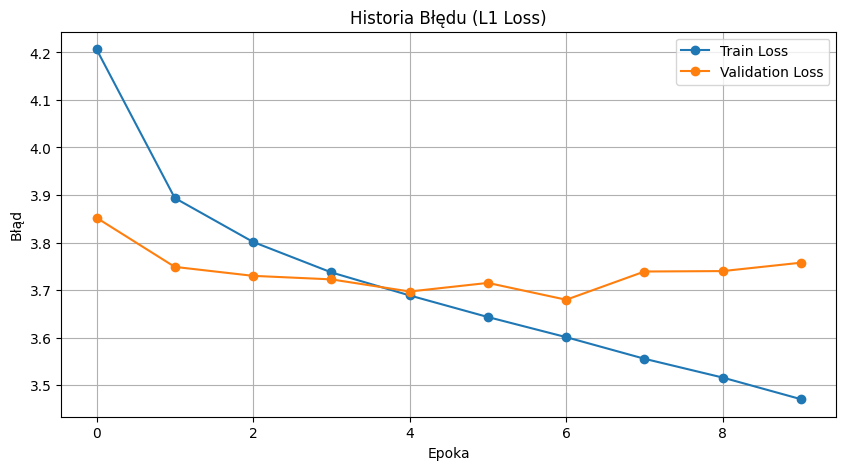

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='o')
plt.title('Loss History (L1 Loss)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

###Visualization

In [ ]:
def visualize_predictions1(model, dataloader, pts, device="cuda", num_imgs=3):
    model.eval()

    inputs, targets = next(iter(dataloader))
    inputs, targets = inputs.to(device), targets.to(device)

    with torch.no_grad():
        outputs = model(inputs)                             # (B, 313, H, W)

    # Denormalize L: [0,1] → [0,100]
    inputs_cpu = inputs[:num_imgs].cpu().squeeze(1).numpy() * 100.0
    targets_cpu = targets[:num_imgs].cpu().numpy()
    outputs_cpu = outputs[:num_imgs].cpu()

    pts_np = pts.cpu().numpy() if isinstance(pts, torch.Tensor) else pts
    pts_tensor = torch.from_numpy(pts_np).float()           # (313, 2)

    fig, axes = plt.subplots(num_imgs, 3, figsize=(12, 4 * num_imgs))
    if num_imgs == 1:
        axes = [axes]

    for i in range(num_imgs):
        L = inputs_cpu[i]                                   # (H, W), range [0, 100]

        # --- Ground Truth ---
        ab_true = pts_np[targets_cpu[i]]                    # (H, W, 2)
        lab_true = np.stack([L, ab_true[:,:,0], ab_true[:,:,1]], axis=-1)
        rgb_true = lab2rgb(lab_true)

        # --- Prediction (annealed mean of Zhang) ---
        T = 0.38
        probs = F.softmax(outputs_cpu[i] / T, dim=0)        # (313, H, W)
        probs = probs.permute(1, 2, 0)                      # (H, W, 313)
        ab_pred = (probs.unsqueeze(-1) * pts_tensor).sum(dim=2).numpy()  # (H, W, 2)
        lab_pred = np.stack([L, ab_pred[:,:,0], ab_pred[:,:,1]], axis=-1)
        rgb_pred = lab2rgb(lab_pred)

        # --- Drawing ---
        axes[i][0].imshow(L, cmap='gray')
        axes[i][0].set_title("Input (L)")
        axes[i][0].axis('off')

        axes[i][1].imshow(np.clip(rgb_pred, 0, 1))
        axes[i][1].set_title(f"Prediction (T={T})")
        axes[i][1].axis('off')

        axes[i][2].imshow(np.clip(rgb_true, 0, 1))
        axes[i][2].set_title("Ground Truth (quantized)")
        axes[i][2].axis('off')

    plt.tight_layout()
    plt.show()

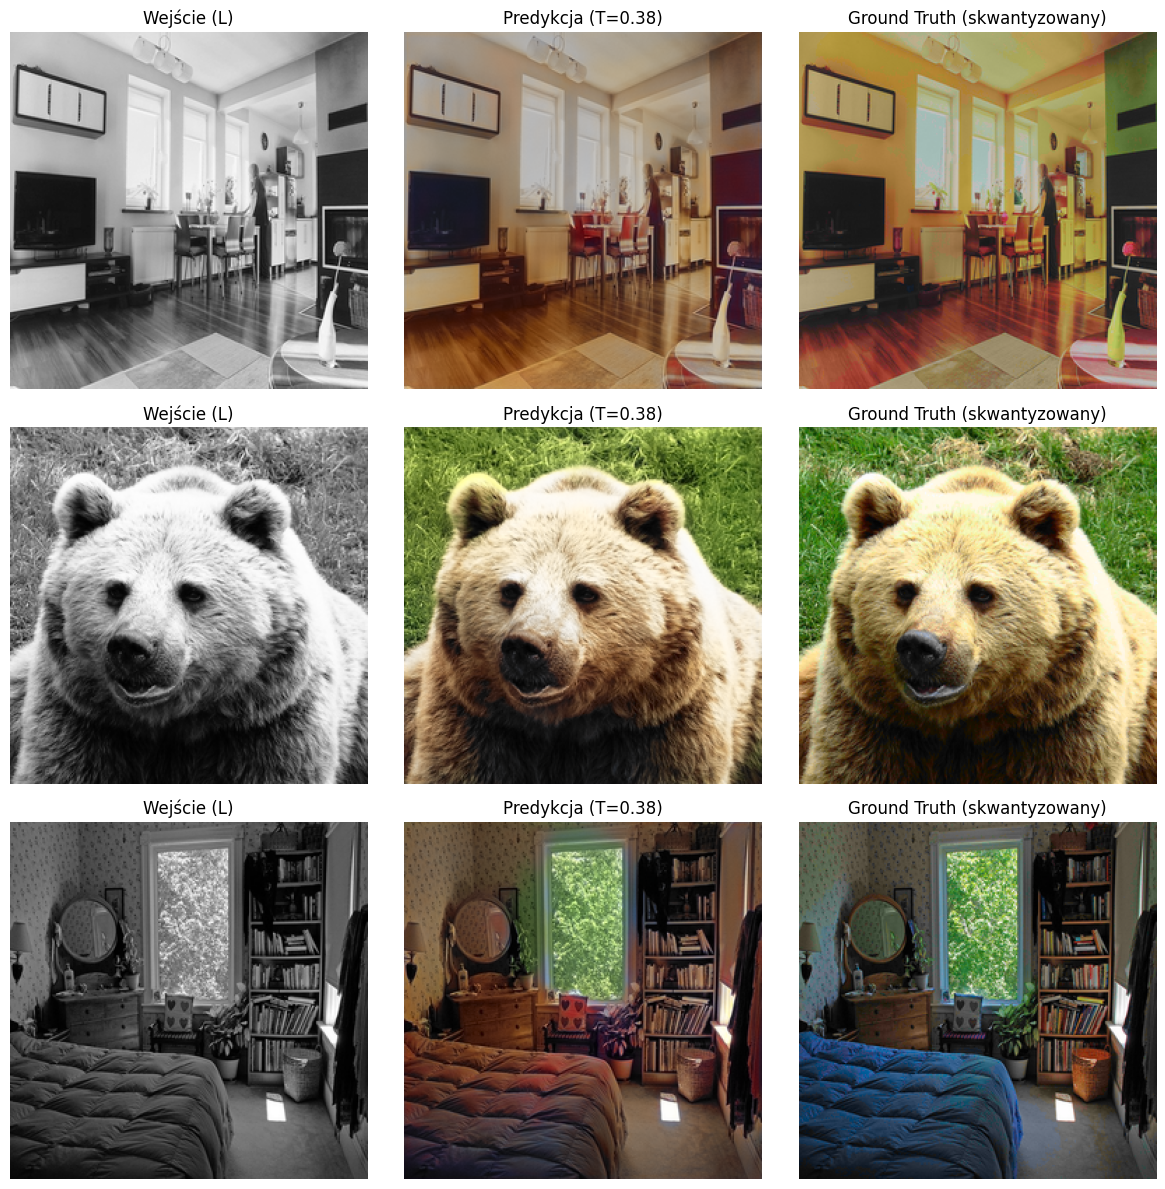

In [ ]:
colorizer_1 = ColorizationUNet().to(device)
colorizer_1.load_state_dict(torch.load("unet_pretrained.pth"))
colorizer_1.eval()
visualize_predictions1(colorizer_1, val_loader, pts, device=device, num_imgs=3)




The model correctly colorizes objects with predictable colors — bear fur, wooden floor, greenery outside the window. The colors are coherent and natural, though sometimes less saturated than ground truth (living room, blanket).

This is typical behavior of a model trained with classification alone — without an adversarial signal, the network "safely" averages colors instead of taking risks. To improve saturation and color sharpness, the next step is to add a PatchGAN discriminator and train in a GAN scheme.



---
## Generative Adversarial Network

### Data Pipeline — Changes for GAN

`COCOColorizationDatasetGAN` extends the pre-training logic with a third output element:
- **L** — lightness channel (range [-1, 1], replicated ×3 in generator)
- **target** — Zhang class indices (for Zhang loss)
- **ab_real** — continuous ab channels / 128 (for L1 loss and discriminator)

Images with low color variance (`std(ab) < 0.5`) are skipped — this prevents dominance of grayscale/beige photos in the dataset.

Augmentation (training only): random horizontal flip, random crop, brightness perturbation ±15%.

Dataset parameters: **30 000 train / 3 000 val**, batch_size=8, num_workers=4.

In [ ]:
class COCOColorizationDatasetGAN(Dataset):
    def __init__(self, raw_dir, pts, img_size=256, max_imgs=5000, augment=False):
        self.raw_dir = raw_dir
        self.image_files = [f for f in os.listdir(raw_dir) if f.endswith('.jpg')][:max_imgs]
        self.resize = transforms.Resize((img_size, img_size), Image.Resampling.LANCZOS)
        self.img_size = img_size
        self.augment = augment
        self.pts = torch.from_numpy(pts).float()

        self.augmentation = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomResizedCrop(
                size=(img_size, img_size),
                scale=(0.8, 1.0),
                ratio=(0.9, 1.1),
                interpolation=Image.Resampling.LANCZOS
            ),
        ]) if augment else None

        self.brightness_range = (0.85, 1.15) if augment else None

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        while True:
            img_path = os.path.join(self.raw_dir, self.image_files[idx])
            img = Image.open(img_path).convert("RGB")
            img = self.resize(img)

            if self.augment and self.augmentation is not None:
                img = self.augmentation(img)

            img_lab = rgb2lab(np.array(img)).astype(np.float32)

            ab_channels = img_lab[:, :, 1:]
            if np.std(ab_channels) < 0.5:
                idx = np.random.randint(0, len(self.image_files))
                continue
            break

        L_raw = img_lab[:, :, 0]
        if self.augment and self.brightness_range is not None:
            brightness_factor = random.uniform(*self.brightness_range)
            L_raw = np.clip(L_raw * brightness_factor, 0.0, 100.0)

        L = L_raw / 50.0 - 1.0
        ab = img_lab[:, :, 1:]

        L_tensor = torch.from_numpy(L).unsqueeze(0).float()
        ab_tensor = torch.from_numpy(ab)

        ab_flat = ab_tensor.view(-1, 2)
        distances = torch.cdist(ab_flat, self.pts)
        target_classes_flat = torch.argmin(distances, dim=1)
        target_tensor = target_classes_flat.view(self.img_size, self.img_size).long()

        ab_tensor_out = ab_tensor.permute(2, 0, 1).float() / 128.0

        return L_tensor, target_tensor, ab_tensor_out

In [ ]:
train_dataset_gan = COCOColorizationDatasetGAN(
    TRAIN_DIR, pts=pts, img_size=256, max_imgs=30000, augment=True)

val_dataset_gan = COCOColorizationDatasetGAN(
    VAL_DIR, pts=pts, img_size=256, max_imgs=1000, augment=False)

train_loader_gan = DataLoader(
    train_dataset_gan, batch_size=8, shuffle=True, drop_last=True,
    num_workers=0, pin_memory=True, persistent_workers=False)

val_loader_gan = DataLoader(
    val_dataset_gan, batch_size=8, shuffle=False, drop_last=False,
    num_workers=0, pin_memory=True, persistent_workers=False)

print(f"GAN — training batches: {len(train_loader_gan)} | validation: {len(val_loader_gan)}")


GAN — paczki treningowe: 3750 | walidacyjne: 125


---
### PatchGAN Discriminator

`PatchGANDiscriminator` evaluates the realism of colorization not for the entire image, but locally — producing a prediction map of size 30×30, where each element is responsible for a receptive field in the input image. This allows the model to focus on texture and color details instead of global coherence.

**Key elements:**
- `features = [64, 128, 256, 512]` — four convolutional layers with progressively increasing number of filters
- `spectral_norm` — spectral normalization stabilizes GAN training by limiting the Lipschitz constant of the discriminator
- `InstanceNorm2d + LeakyReLU(0.2)` — standard block for PatchGAN; InstanceNorm works better than BatchNorm with small batch sizes

- Input is concatenation of lightness channel `L` and color channels `ab` → tensor `[B, 3, H, W]`; discriminator sees both image structure and colorization
- Output `[B, 1, 30×30]` used by LSGAN (MSELoss instead of BCELoss) for more stable gradients

In [ ]:
class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_channels=3, features=[64, 128, 256, 512]):
        super().__init__()

        # First layer — without normalization (standard PatchGAN)
        layers = [
            spectral_norm(nn.Conv2d(in_channels, features[0], kernel_size=4, stride=2, padding=1)),
            nn.LeakyReLU(0.2, inplace=True)
        ]

        in_ch = features[0]
        for i, feat in enumerate(features[1:]):
            stride = 1 if i == len(features) - 2 else 2
            layers += [
                spectral_norm(nn.Conv2d(in_ch, feat, kernel_size=4, stride=stride, padding=1, bias=False)),
                nn.InstanceNorm2d(feat),        # Does not conflict with spectral_norm
                nn.LeakyReLU(0.2, inplace=True)
            ]
            in_ch = feat

        # PatchGAN output: 30×30 map of judgments for 70×70 patches
        layers.append(nn.Conv2d(in_ch, 1, kernel_size=4, stride=1, padding=1))

        self.model = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0.0, 0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, L, ab):
        x = torch.cat([L, ab], dim=1)   # [B, 3, H, W]
        return self.model(x)             # [B, 1, 30, 30]



---
### GAN Training — Training Loop

Each iteration consists of two alternating steps:

1. **Step D (Discriminator):** distinguishes real colors from generator predictions
2. **Step G (Generator):** minimizes Zhang loss + L1 loss + adversarial loss *(only after warmup)*

**Warmup (first 5 epochs):** we train only the generator (without discriminator) so G learns the basics before D starts correcting it. In this phase, G loss = Zhang loss + L1 loss. This prevents instability at the beginning of GAN training.

**Generator loss weights:**
- `lambda_zhang = 1.0` — ab bin classification (main component)
- `lambda_l1 = 10.0` — color coherence with ground truth
- `lambda_adv = 0.1` — signal from discriminator *(active from epoch 6)*

In [ ]:
def logits_to_ab(logits, pts_tensor, T=0.38):
    """Converts 313 class logits → continuous ab through weighted sum (Zhang annealed mean)."""
    probs = F.softmax(logits / T, dim=1)        # (B, 313, H, W)
    probs = probs.permute(0, 2, 3, 1)           # (B, H, W, 313)
    ab    = torch.matmul(probs, pts_tensor)      # (B, H, W, 2)
    return ab.permute(0, 3, 1, 2) / 128.0       # (B, 2, H, W), range [-1, 1]


def train_gan(
    generator, discriminator,
    train_loader, val_loader,
    class_weights, pts,
    epochs=15,
    lr_G=2e-4,
    lr_D=5e-5,
    device="cuda",
    patience=7,
    accumulation_steps=2,
    lambda_zhang=1.0,
    lambda_adv=0.1,
    lambda_l1=10.0,
    T=0.38,
    warmup_epochs=5         # first N epochs: G only, no D
):
    pts_tensor = (pts if isinstance(pts, torch.Tensor)
                  else torch.from_numpy(pts).float()).to(device)

    criterion_zhang = ZhangRebalancedLoss(class_weights)
    criterion_GAN   = nn.MSELoss()                          # LSGAN

    optimizer_G = optim.Adam(generator.parameters(),     lr=lr_G, betas=(0.5, 0.999))
    optimizer_D = optim.Adam(discriminator.parameters(), lr=lr_D, betas=(0.5, 0.999))

    scheduler_G = optim.lr_scheduler.ReduceLROnPlateau(optimizer_G, mode='min', factor=0.5, patience=3, verbose=True)
    scheduler_D = optim.lr_scheduler.ReduceLROnPlateau(optimizer_D, mode='min', factor=0.5, patience=3, verbose=True)

    scaler = torch.amp.GradScaler('cuda')

    train_losses_G, train_losses_D, val_losses = [], [], []
    best_val_loss     = float('inf')
    epochs_no_improve = 0

    print(f"GAN Training | Epochs: {epochs} | Warmup: {warmup_epochs} | "
          f"lr_G: {lr_G} | lr_D: {lr_D} | λ_adv: {lambda_adv} | λ_zhang: {lambda_zhang} | λ_l1: {lambda_l1}")

    for epoch in range(epochs):
        is_warmup = epoch < warmup_epochs
        if is_warmup:
            print(f"[Warmup {epoch+1}/{warmup_epochs}] Training generator only.")

        generator.train()
        discriminator.train()

        running_loss_G = running_loss_D = 0.0
        optimizer_G.zero_grad()
        optimizer_D.zero_grad()

        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [GAN]")

        for i, (L, target, ab_real) in enumerate(train_pbar):
            L       = L.to(device, non_blocking=True)
            target  = target.to(device, non_blocking=True)
            ab_real = ab_real.to(device, non_blocking=True)

            # ── STEP D (only after warmup) ──────────────────────────────────
            if not is_warmup:
                with torch.amp.autocast('cuda'):
                    logits  = generator(L)
                    ab_fake = logits_to_ab(logits, pts_tensor, T)

                    real_pred = discriminator(L, ab_real)
                    fake_pred = discriminator(L, ab_fake.detach())

                    loss_D = (criterion_GAN(real_pred, torch.ones_like(real_pred)) +
                              criterion_GAN(fake_pred, torch.zeros_like(fake_pred))) * 0.5
                    loss_D = loss_D / accumulation_steps

                scaler.scale(loss_D).backward()
                running_loss_D += (loss_D.item() * accumulation_steps) * L.size(0)

            # ── STEP G ──────────────────────────────────────────────────────
            for p in discriminator.parameters():
                p.requires_grad_(False)

            with torch.amp.autocast('cuda'):
                logits  = generator(L)
                ab_fake = logits_to_ab(logits, pts_tensor, T)

                loss_G_zhang = criterion_zhang(logits, target)
                loss_G_l1    = F.l1_loss(ab_fake, ab_real)

                if is_warmup:
                    loss_G = (lambda_zhang * loss_G_zhang + lambda_l1 * loss_G_l1) / accumulation_steps
                else:
                    fake_pred_G = discriminator(L, ab_fake)
                    loss_G_adv  = criterion_GAN(fake_pred_G, torch.ones_like(fake_pred_G))
                    loss_G = (lambda_adv   * loss_G_adv  +
                              lambda_zhang * loss_G_zhang +
                              lambda_l1   * loss_G_l1) / accumulation_steps

            scaler.scale(loss_G).backward()

            for p in discriminator.parameters():
                p.requires_grad_(True)

            # ── WEIGHT UPDATE ────────────────────────────────────────────────
            if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
                if not is_warmup:
                    scaler.unscale_(optimizer_D)
                    nn.utils.clip_grad_norm_(discriminator.parameters(), max_norm=1.0)
                    scaler.step(optimizer_D)

                scaler.unscale_(optimizer_G)
                nn.utils.clip_grad_norm_(generator.parameters(), max_norm=1.0)
                scaler.step(optimizer_G)

                scaler.update()
                optimizer_D.zero_grad()
                optimizer_G.zero_grad()

            running_loss_G += (loss_G.item() * accumulation_steps) * L.size(0)

            train_pbar.set_postfix({
                "G": f"{loss_G.item()*accumulation_steps:.4f}",
                "D": f"{running_loss_D/(i+1):.4f}" if not is_warmup else "warmup",
                "lr_G": f"{optimizer_G.param_groups[0]['lr']:.2e}"
            })

        epoch_loss_G = running_loss_G / len(train_loader.dataset)
        epoch_loss_D = running_loss_D / len(train_loader.dataset)

        # ── VALIDATION ────────────────────────────────────────────────────────
        generator.eval()
        running_val_loss = 0.0
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Validation]")

        with torch.no_grad():
            for L, target, ab_real in val_pbar:
                L       = L.to(device, non_blocking=True)
                target  = target.to(device, non_blocking=True)
                ab_real = ab_real.to(device, non_blocking=True)

                with torch.amp.autocast('cuda'):
                    logits  = generator(L)
                    ab_fake = logits_to_ab(logits, pts_tensor, T)
                    val_loss = (lambda_zhang * criterion_zhang(logits, target) +
                                lambda_l1   * F.l1_loss(ab_fake, ab_real))

                running_val_loss += val_loss.item() * L.size(0)
                val_pbar.set_postfix({"Val": f"{val_loss.item():.4f}"})

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        train_losses_G.append(epoch_loss_G)
        train_losses_D.append(epoch_loss_D)
        val_losses.append(epoch_val_loss)

        scheduler_G.step(epoch_val_loss)
        scheduler_D.step(epoch_val_loss)

        print(f">>> Epoch {epoch+1}: G = {epoch_loss_G:.4f} | "
              f"D = {epoch_loss_D:.4f} | Val = {epoch_val_loss:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            epochs_no_improve = 0
            torch.save({
                'epoch':                    epoch+1,
                'generator_state_dict':     generator.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_G_state_dict':   optimizer_G.state_dict(),
                'optimizer_D_state_dict':   optimizer_D.state_dict(),
                'scheduler_G_state_dict':   scheduler_G.state_dict(),
                'scheduler_D_state_dict':   scheduler_D.state_dict(),
                'best_val_loss':            best_val_loss,
                'train_losses_G':           train_losses_G,
                'train_losses_D':           train_losses_D,
                'val_losses':               val_losses,
            }, "gan_best.pth")
            print(f"[*] Checkpoint saved. (Val: {best_val_loss:.4f})\n")
        else:
            epochs_no_improve += 1
            print(f"[-] No improvement for {epochs_no_improve}/{patience} epochs.\n")
            if epochs_no_improve >= patience:
                print(f"!!! Early Stopping after {epoch+1} epochs.")
                break

    torch.save(generator.state_dict(), "gan_generator_final.pth")
    print("Final generator saved.")
    return train_losses_G, train_losses_D, val_losses

In [ ]:
generator = ColorizationUNet().to(device)
generator.load_state_dict(torch.load("unet_pretrained_best.pth", weights_only=True))

discriminator = PatchGANDiscriminator().to(device)


train_gan(
    generator=generator,
    discriminator=discriminator,
    train_loader=train_loader_gan,
    val_loader=val_loader_gan,
    pts=pts,
    class_weights=class_weights,
    epochs=15,
    lr_G=2e-4,
    lr_D=5e-5,
    device=device
)

Trening GAN | Epoki: 15 | Warmup: 5 | lr_G: 0.0002 | lr_D: 5e-05 | λ_adv: 0.1 | λ_zhang: 1.0 | λ_l1: 10.0
[Warmup 1/5] Trenuje tylko generator.


Epoka 1/15 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:30<00:00,  1.39it/s, Val=3.4164]


>>> Epoka 1: G = 4.0947 | D = 0.0000 | Val = 4.4916
[*] Checkpoint zapisany. (Val: 4.4916)

[Warmup 2/5] Trenuje tylko generator.


Epoka 2/15 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:38<00:00,  1.27it/s, Val=3.3506]


>>> Epoka 2: G = 4.0312 | D = 0.0000 | Val = 4.5002
[-] Brak poprawy od 1/7 epok.

[Warmup 3/5] Trenuje tylko generator.


...

Epoka 9/15 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:31<00:00,  1.36it/s, Val=3.2866]


>>> Epoka 9: G = 3.6967 | D = 0.1620 | Val = 4.6614
[-] Brak poprawy od 6/7 epok.



Epoka 10/15 [Walidacja]: 100%|███████████████████████████████████████████| 125/125 [01:45<00:00,  1.19it/s, Val=3.2506]


>>> Epoka 10: G = 3.6657 | D = 0.1528 | Val = 4.6565
[-] Brak poprawy od 7/7 epok.

!!! Early Stopping po 10 epokach.
Zapisano finalny generator.


([4.094746544202168,
  4.031230308723449,
  3.9776361464182535,
  3.928610289891561,
  3.87857627919515,
  3.872801268641154,
  3.838470444869995,
  3.7449333974838255,
  3.6966618339538573,
  3.6657414752324424],
 [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.27502112668355305,
  0.22936338067849477,
  0.17297906388441722,
  0.16197418413360914,
  0.15279902708331744],
 [4.4916486740112305,
  4.500204908370971,
  4.475252799987793,
  4.476031925201416,
  4.499112125396729,
  4.524573793411255,
  4.56194578742981,
  4.657636701583862,
  4.661355253219605,
  4.6565479526519775])

Training ended prematurely after 10 epochs (early stopping, patience=7). The best checkpoint comes from **epoch 3** (Val = 4.4753) — still in the warmup phase, before the discriminator started training.

From epoch 6 onwards (discriminator entry) Val loss increased consistently: 4.52 → 4.56 → 4.66, indicating a conflict between an overly strong L1 penalty (`lambda_l1 = 10.0`) and the adversarial signal. The generator was "forced" to match pixel-wise accuracy with ground truth instead of learning realistic color patterns from the discriminator. As a result, the signal from D was effectively suppressed — `lambda_adv = 0.1` turned out to be too small relative to the dominant L1 loss.

### GAN Results Visualization

The function displays three columns for each image: input (lightness channel L), GAN prediction, and ground truth. Colors are reconstructed using Zhang annealed mean method (temperature `T=0.38`), which sharpens the probability distribution over 313 ab bins and produces more saturated colors than simple argmax.

In [ ]:
def visualize_predictions2(model, dataloader, pts, device="cuda", num_imgs=3):
    model.eval()

    inputs, targets, _ = next(iter(dataloader))   # val_loader_gan returns 3 values
    inputs, targets = inputs.to(device), targets.to(device)

    with torch.no_grad():
        outputs = model(inputs)                    # (B, 313, H, W)

    # Denormalize L: [-1,1] → [0,100]  (GAN normalizes differently than pre-train)
    inputs_cpu = (inputs[:num_imgs].cpu().squeeze(1).numpy() + 1.0) * 50.0
    targets_cpu = targets[:num_imgs].cpu().numpy()
    outputs_cpu = outputs[:num_imgs].cpu()

    pts_np = pts.cpu().numpy() if isinstance(pts, torch.Tensor) else pts
    pts_tensor = torch.from_numpy(pts_np).float()

    fig, axes = plt.subplots(num_imgs, 3, figsize=(12, 4 * num_imgs))
    if num_imgs == 1:
        axes = [axes]

    for i in range(num_imgs):
        L = inputs_cpu[i]                          # (H, W), range [0, 100]

        # --- Ground Truth ---
        ab_true = pts_np[targets_cpu[i]]
        lab_true = np.stack([L, ab_true[:,:,0], ab_true[:,:,1]], axis=-1)
        rgb_true = lab2rgb(lab_true)

        # --- Prediction ---
        T = 0.38
        probs = F.softmax(outputs_cpu[i] / T, dim=0).permute(1, 2, 0)  # (H, W, 313)
        ab_pred = (probs.unsqueeze(-1) * pts_tensor).sum(dim=2).numpy() # (H, W, 2)
        lab_pred = np.stack([L, ab_pred[:,:,0], ab_pred[:,:,1]], axis=-1)
        rgb_pred = lab2rgb(lab_pred)

        axes[i][0].imshow(L, cmap='gray');             axes[i][0].set_title("Input (L)")
        axes[i][1].imshow(np.clip(rgb_pred, 0, 1));    axes[i][1].set_title(f"GAN Prediction (T={T})")
        axes[i][2].imshow(np.clip(rgb_true, 0, 1));    axes[i][2].set_title("Ground Truth")
        for ax in axes[i]: ax.axis('off')

    plt.tight_layout()
    plt.show()

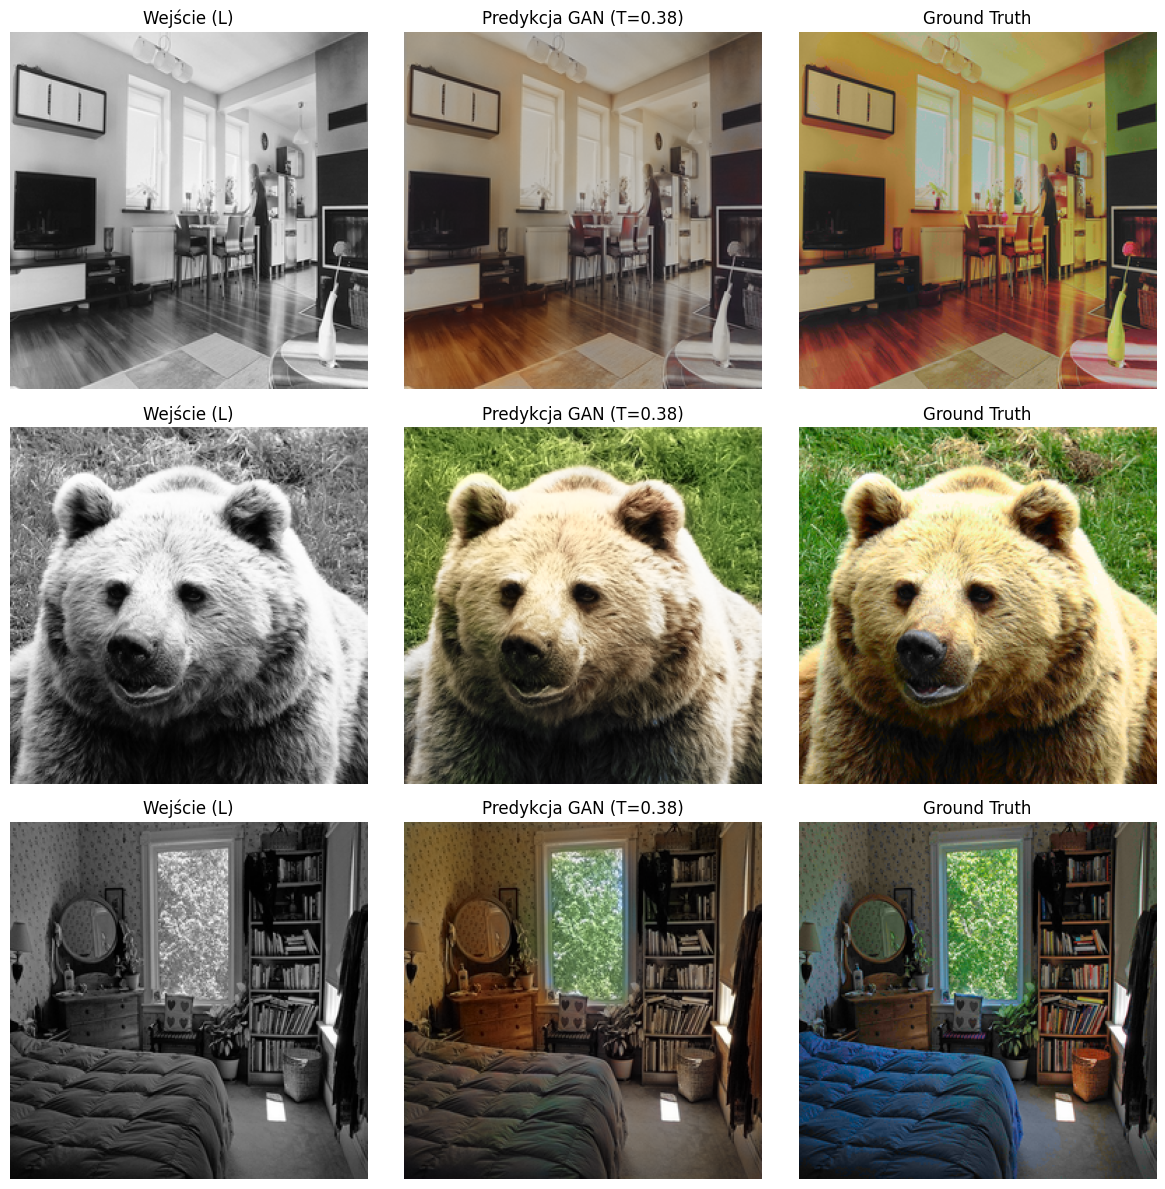

In [ ]:
colorizer_gan = ColorizationUNet().to(device)
colorizer_gan.load_state_dict(torch.load("gan_best.pth")['generator_state_dict'])
colorizer_gan.eval()

visualize_predictions2(colorizer_gan, val_loader_gan, pts, device=device, num_imgs=3)

The results of the first GAN loop did not bring significant improvement over the pre-trained U-Net. The excessively high value of `lambda_l1 = 10.0` suppressed the adversarial signal, preventing the discriminator from having real influence on colorization quality. Training ended prematurely after 10 epochs — the best checkpoint comes from epoch 3, still in the warmup phase.


---
## Final Fine-Tuning

To improve the results, we resume training from that checkpoint, correcting the main cause of failure. Reducing `lambda_l1` to 2.0 gives the discriminator real influence over colorization, increased `lambda_adv = 0.2` strengthens its signal, and lower `lr_G = 1e-4` ensures more stable convergence. We skip warmup — the generator is already trained.

In [ ]:
ckpt = torch.load("gan_best.pth")
generator.load_state_dict(ckpt['generator_state_dict'])
discriminator.load_state_dict(ckpt['discriminator_state_dict'])

train_gan(
    generator=generator,
    discriminator=discriminator,
    train_loader=train_loader_gan,
    val_loader=val_loader_gan,
    class_weights=class_weights,
    pts=pts,
    device=device,
    lambda_l1=2.0,
    lambda_adv=0.2,
    warmup_epochs=0,
    epochs=10,
    lr_G=1e-4,
    lr_D=5e-5,
)


Trening GAN | Epoki: 10 | Warmup: 0 | lr_G: 0.0001 | lr_D: 5e-05 | λ_adv: 0.2 | λ_zhang: 1.0 | λ_l1: 2.0


Epoka 1/10 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:30<00:00,  1.37it/s, Val=2.9865]


>>> Epoka 1: G = 3.4378 | D = 0.2752 | Val = 3.9522
[*] Checkpoint zapisany. (Val: 3.9522)



Epoka 2/10 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:34<00:00,  1.32it/s, Val=2.8612]


>>> Epoka 2: G = 3.3945 | D = 0.2342 | Val = 4.0056
[-] Brak poprawy od 1/7 epok.



...

Epoka 7/10 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:28<00:00,  1.42it/s, Val=2.9024]


>>> Epoka 7: G = 3.2912 | D = 0.1662 | Val = 4.1508
[-] Brak poprawy od 6/7 epok.



Epoka 8/10 [Walidacja]: 100%|████████████████████████████████████████████| 125/125 [01:38<00:00,  1.27it/s, Val=2.8859]


>>> Epoka 8: G = 3.2770 | D = 0.1621 | Val = 4.1643
[-] Brak poprawy od 7/7 epok.

!!! Early Stopping po 8 epokach.
Zapisano finalny generator.


([3.437767345937093,
  3.394453749211629,
  3.401239504877726,
  3.3894001881281537,
  3.3640328559875488,
  3.3191529562632245,
  3.2912283791224164,
  3.2769750100453696],
 [0.27517949187755586,
  0.23420461270014445,
  0.18992159958283106,
  0.18147892741362254,
  0.184722634100914,
  0.16630415180921554,
  0.1662162775973479,
  0.1620781418800354],
 [3.9521644287109376,
  4.0056189460754394,
  4.0733697204589845,
  4.116997222900391,
  4.153077121734619,
  4.137961797714233,
  4.150839942932129,
  4.1642773113250735])

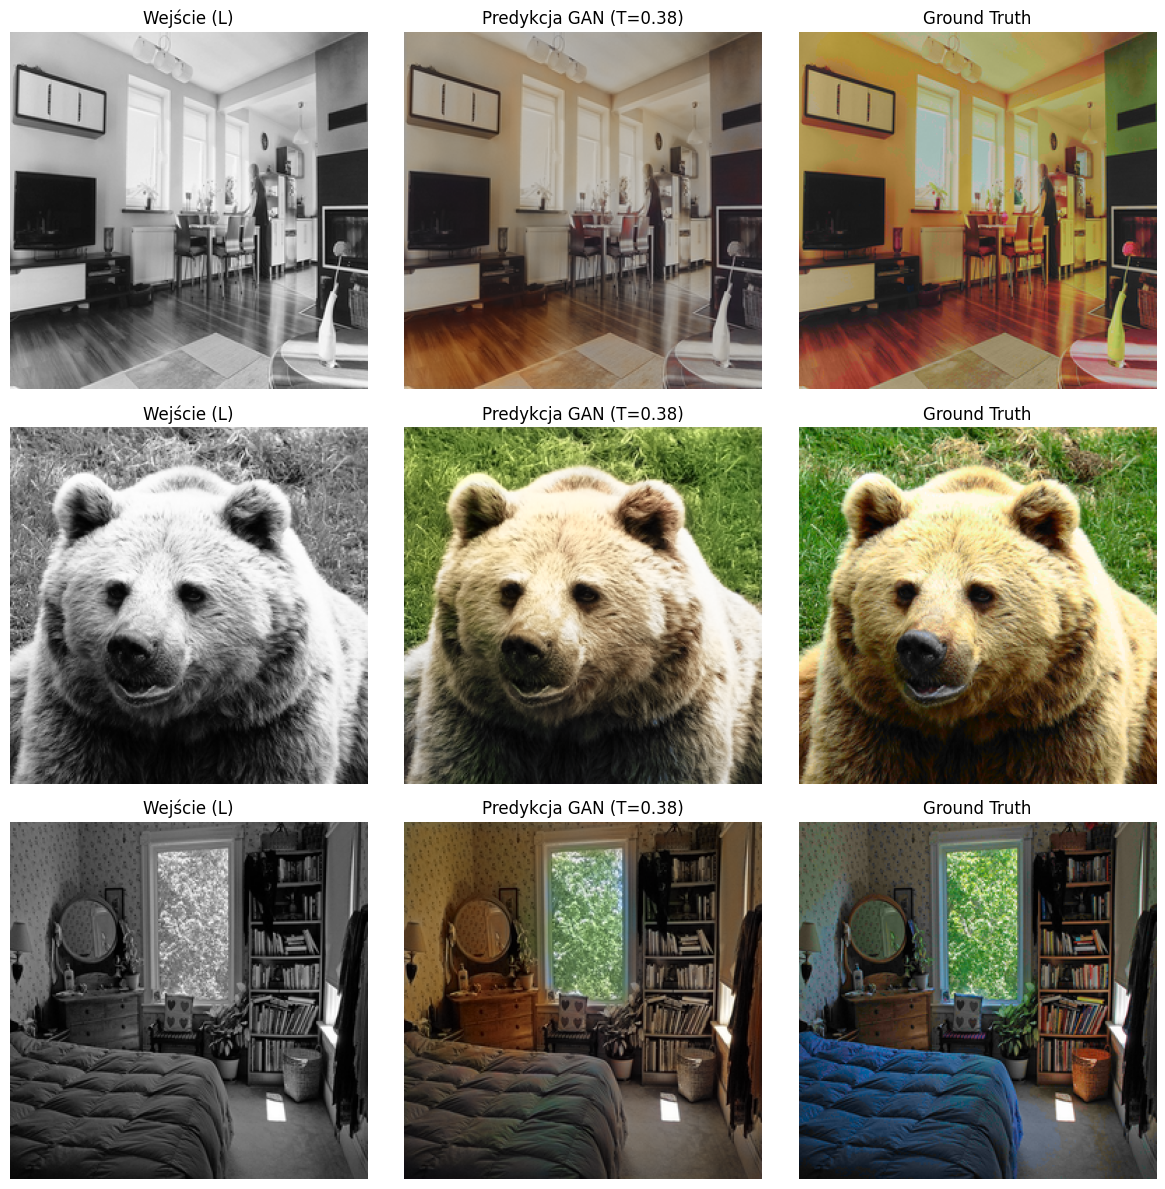

In [ ]:
colorizer_gan = ColorizationUNet().to(device)
colorizer_gan.load_state_dict(torch.load("gan_best (1).pth")['generator_state_dict'])
colorizer_gan.eval()

visualize_predictions2(colorizer_gan, val_loader_gan, pts, device=device, num_imgs=3)

---
# Final Summary

Despite two complete GAN training loops, neither brought measurable visual improvement over the pre-trained U-Net. The model encountered a fundamental limitation: the validation metric (Zhang loss + L1) increased from the second epoch in both cases, resulting in early training termination after just 8 epochs.

The achieved results demonstrate, however, that the hybrid U-Net architecture with EfficientNet-B4 encoder and Zhang quantization provides a solid foundation for image colorization. The network correctly recognizes scene semantics and assigns credible colors to most objects, and the pre-training results are visually satisfactory. Further improvements would require longer GAN training, a larger dataset, or a change in encoder architecture to a more global approach — such as Swin Transformer.